1. Data Preprocessing
•	Load the dataset using Pandas.

•	Inspect the dataset using head(), info(), describe(), and isnull().sum().

•	Identify and handle missing values and duplicate records.

•	Separate input features from the target variable.

•	Encode categorical features, such as internship status, using one-hot encoding.

•	Standardize numerical features using StandardScaler.

•	Split the dataset into training and testing sets, such as 80% for training and 20% for testing.

•	Use stratified splitting to preserve the approximate class distribution.


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PolynomialFeatures, OneHotEncoder

In [6]:
df = pd.read_csv("C:\ML Practical\student_placement_dataset.csv")

In [7]:
print(df.head())         
print(df.info())          
print(df.describe())      
print(df.isnull().sum())  

   CGPA  AptitudeScore  TechnicalScore  CommunicationScore Internship  \
0  7.36           45.2            54.4                79.6         No   
1  6.22           57.7            78.7                99.8         No   
2  7.74           71.3            66.8                46.5         No   
3  7.90           63.5            50.1                86.4        Yes   
4  5.44           55.2            47.3                67.0         No   

   Placement  
0          0  
1          0  
2          1  
3          0  
4          0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1210 entries, 0 to 1209
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   CGPA                1190 non-null   float64
 1   AptitudeScore       1177 non-null   float64
 2   TechnicalScore      1192 non-null   float64
 3   CommunicationScore  1185 non-null   float64
 4   Internship          1189 non-null   object 
 5   Placement        

In [26]:
# Remove duplicate rows
df = df.drop_duplicates()

# Fill missing numerical values with mean
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
df[num_cols] = df[num_cols].fillna(df[num_cols].mean())

# Fill missing categorical values with mode
cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [27]:
df

,CGPA,AptitudeScore,TechnicalScore,CommunicationScore,Internship,Placement
0,7.36,45.2,54.4,79.6,No,0
1,6.22,57.7,78.7,99.8,No,0
2,7.74,71.3,66.8,46.5,No,1
3,7.90,63.5,50.1,86.4,Yes,0
4,5.44,55.2,47.3,67.0,No,0
...,...,...,...,...,...,...
1195,8.77,47.6,100.0,53.7,Yes,1
1196,6.06,58.4,54.7,70.9,No,0
1197,6.31,62.3,52.3,77.8,No,0
1198,8.36,55.3,31.8,59.7,Yes,0


In [28]:
#Separate input features from the target variable.

X = df.drop("Placement", axis=1)
y = df["Placement"]

In [29]:
#Encode categorical features, such as internship status, using one-hot encoding.
X = pd.get_dummies(X, drop_first=True)

In [31]:
#Standardize numerical features using StandardScaler.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [32]:
#Split the dataset into training and testing sets, such as 80% for training and 20% for testing.
#Use stratified splitting to preserve the approximate class distribution.

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

2. Exploratory Data Analysis (EDA)

•	Analyze the distribution of placed and unplaced students.

•	Plot the relationship between CGPA and placement.

•	Compare technical and aptitude scores across placement outcomes.

•	Generate a correlation heatmap for numerical features.

•	Identify potential class imbalance and relationships between features and the target.


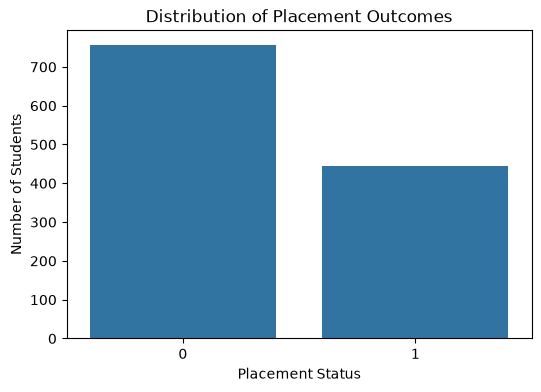

Placement
0    63.0
1    37.0
Name: proportion, dtype: float64


In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count plot of placement status
plt.figure(figsize=(6,4))
sns.countplot(x='Placement', data=df)
plt.title('Distribution of Placement Outcomes')
plt.xlabel('Placement Status')
plt.ylabel('Number of Students')
plt.show()

# Percentage distribution
print(df['Placement'].value_counts(normalize=True) * 100)

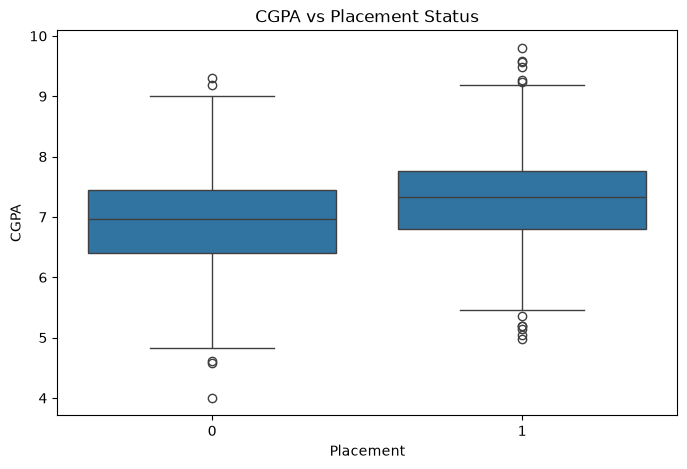

In [37]:
plt.figure(figsize=(8,5))
sns.boxplot(x='Placement', y='CGPA', data=df)
plt.title('CGPA vs Placement Status')
plt.show()

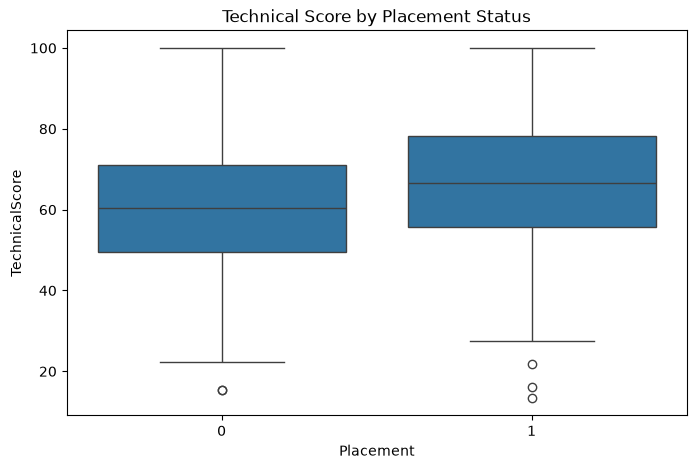

In [39]:
plt.figure(figsize=(8,5))
sns.boxplot(x='Placement', y='TechnicalScore', data=df)
plt.title('Technical Score by Placement Status')
plt.show()

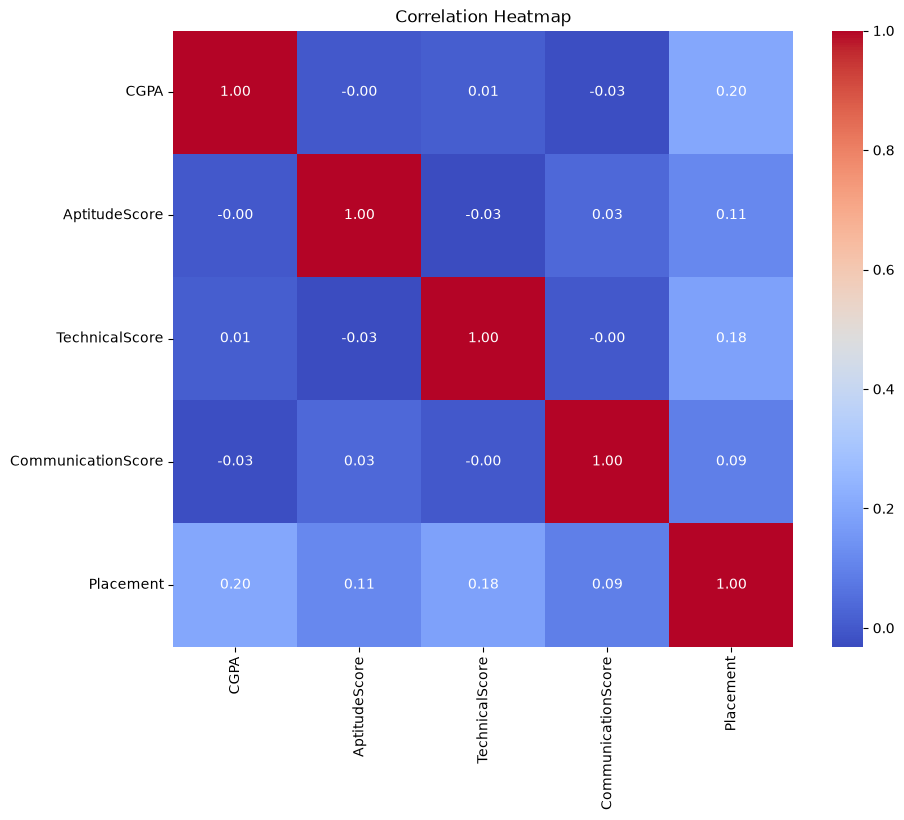

In [40]:
plt.figure(figsize=(10,8))

corr_matrix = df.select_dtypes(include=['int64','float64']).corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

In [42]:
placement_counts = df['Placement'].value_counts()

print(placement_counts)

print("\nPercentage Distribution:")
print(df['Placement'].value_counts(normalize=True) * 100)

Placement
0    756
1    444
Name: count, dtype: int64

Percentage Distribution:
Placement
0    63.0
1    37.0
Name: proportion, dtype: float64


3. Model Building

Build a Logistic Regression classification model using Scikit-learn.

The model estimates the probability of placement using the sigmoid function:
\[ P(Y=1\mid X)=\frac{1}{1+e^{-z}} \]

where
\[ z=b_0+b_1x_1+b_2x_2+\cdots+b_nx_n \]

Here, \(b_0\) is the intercept, \(b_i\) are learned coefficients, and \(x_i\) are the input features.
•	Implement Logistic Regression using LogisticRegression().
•	Train the model using fit().
•	Predict placement classes using predict().
•	Calculate placement probabilities using predict_proba().
•	Interpret the model coefficients to understand the direction of learned feature relationships.
